<a href="https://colab.research.google.com/github/Burzo572/dsb_project/blob/main/Logistic_Regression_Modeling_Janko.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.dummy import DummyClassifier

In [3]:
from google.colab import files

uploaded = files.upload()

Saving SW90_Bahadurabad.csv to SW90_Bahadurabad.csv


In [4]:
import pandas as pd

df = pd.read_csv("SW90_Bahadurabad.csv")

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

print("\nStations:")
print(df["station_id"].value_counts())

print("\nFlood labels:")
print(df["flood_within_24h"].value_counts(dropna=False))

print("\nLabel regimes:")
print(df["flood_within_24h_label_regime"].value_counts(dropna=False))

Dataset shape: (3013, 50)
Date range: 2012-12-31 00:00:00 to 2025-12-31 00:00:00

Stations:
station_id
SW90    3013
Name: count, dtype: int64

Flood labels:
flood_within_24h
0.0    2887
1.0     126
Name: count, dtype: int64

Label regimes:
flood_within_24h_label_regime
observed    3013
Name: count, dtype: int64


In [5]:
missing = df.isnull().sum().sort_values(ascending=False)

missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing (%)": missing_percent.reindex(missing.index)})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing (%)
upstream_chain_discharge_lag2d,3013,100.00
upstream_reference_discharge_lag2d,3013,100.00
upstream_reference_discharge_lag3d,3013,100.00
flood_byStor,2914,96.71
rainfall_local_mm_trend_ratio,727,24.13
rainfall_upstream_mm_trend_ratio,13,0.43
flood_within_72h,2,0.07
flood_within_72h_label_regime,2,0.07
flood_within_48h_label_regime,1,0.03
flood_within_48h,1,0.03


In [6]:
columns_to_drop = [
    "upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag2d",
    "upstream_reference_discharge_lag3d",
    "flood_byStor",
    "rainfall_local_mm_trend_ratio",
    "rainfall_upstream_mm_trend_ratio",
    "flood_within_48h",
    "flood_within_48h_label_regime",
    "flood_within_72h",
    "flood_within_72h_label_regime"]

df_model = df.drop(columns=columns_to_drop).copy()

print("Dataset shape:", df_model.shape)
print("\nRemaining columns:")
print(df_model.columns.tolist())

Dataset shape: (3013, 40)

Remaining columns:
['date', 'station_id', 'station_name', 'rainfall_local_mm', 'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s', 'rainfall_local_mm_missing', 'rainfall_upstream_mm_missing', 'soil_moisture_local_missing', 'river_discharge_m3s_missing', 'flood_byStor_missing', 'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d', 'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d', 'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d', 'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d', 'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d', 'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d', 'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d', 'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d', 'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d', 'rainfall_upstream_mm_sum7d', 'rainfall_upstream_mm_sum14d', 'soil_moisture_delta_30d', 'soil_moisture_swi', 'elevation_m', 'hand_m', 'flood_within_24h', 'flood_w

**Temporal Distribution of Flood Labels**

Before splitting the dataset into training, validation, and testing subsets, I examine the distribution of flood labels across years.

The objective is to identify periods with sufficient positive and negative examples and avoid using years with incomplete flood-label coverage.

Since the data represents a time series, chronological splitting will be used instead of random splitting to prevent information from future observations entering the training process.

In [7]:
# Flood label distribution by year
yearly_distribution = (
    df_model.groupby(df_model["date"].dt.year)
    ["flood_within_24h"]
    .agg(
        total_days="count",
        flood_days="sum"))

yearly_distribution["no_flood_days"] = (
    yearly_distribution["total_days"] -
    yearly_distribution["flood_days"])

yearly_distribution["flood_rate_%"] = (
    yearly_distribution["flood_days"] /
    yearly_distribution["total_days"] * 100).round(2)

display(yearly_distribution)

,total_days,flood_days,no_flood_days,flood_rate_%
date,,,,
2012,1,0.0,1.0,0.00
2013,365,10.0,355.0,2.74
2014,365,30.0,335.0,8.22
2015,365,33.0,332.0,9.04
2016,90,0.0,90.0,0.00
2020,1,0.0,1.0,0.00
2021,365,13.0,352.0,3.56
2022,365,19.0,346.0,5.21
2023,365,11.0,354.0,3.01


 **Chronological Train, Validation and Test Split**

I divide the dataset into training, validation, and testing subsets using chronological order.

The training set contains observations from 2013 to 2015, the validation set contains observations from 2021 to 2022, and the test set contains observations from 2023 to 2025.

This approach prevents future observations from being used during model training. The validation set will be used for model selection and threshold tuning, while the test set will be reserved for final performance evaluation.

The gap in historical label coverage and the relatively small number of positive flood cases are important limitations of this experiment.

In [8]:
# Chronological data split
train_df = df_model[
    df_model["date"].dt.year.between(2013, 2015)].copy()

val_df = df_model[
    df_model["date"].dt.year.between(2021, 2022)].copy()

test_df = df_model[
    df_model["date"].dt.year.between(2023, 2025)].copy()

# Check data distribution
for name, dataset in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)]:
    print(f"\n{name}")
    print("Shape:", dataset.shape)
    print(dataset["flood_within_24h"].value_counts())


Training
Shape: (1095, 40)
flood_within_24h
0.0    1022
1.0      73
Name: count, dtype: int64

Validation
Shape: (730, 40)
flood_within_24h
0.0    698
1.0     32
Name: count, dtype: int64

Testing
Shape: (1096, 40)
flood_within_24h
0.0    1075
1.0      21
Name: count, dtype: int64


**Feature Selection for Machine Learning Models**

In this section, I define three groups of environmental features to investigate their contribution to 24-hour flood prediction at SW90 – Bahadurabad.

Model A: Local rainfall, river discharge, soil moisture, and historical environmental conditions.

Model B: Model A features combined with upstream rainfall information.

Model C: Model B features combined with upstream river discharge information.

This incremental approach allows me to compare whether adding upstream environmental variables improves predictive performance.

All three models will use the same chronological training, validation, and testing periods to ensure a consistent comparison.

In [9]:
# Target variable
target = "flood_within_24h"

# Model A - Local environmental conditions
features_A = [
    "rainfall_local_mm",
    "river_discharge_m3s",
    "soil_moisture_local",
    "rainfall_local_mm_lag1d",
    "rainfall_local_mm_lag2d",
    "rainfall_local_mm_sum7d",
    "rainfall_local_mm_sum14d",
    "river_discharge_m3s_lag1d",
    "river_discharge_m3s_lag2d",
    "soil_moisture_local_lag1d",
    "soil_moisture_delta_30d",
    "soil_moisture_swi"]

# Model B - Local + upstream rainfall
features_B = features_A + [
    "rainfall_upstream_mm",
    "rainfall_upstream_mm_lag1d",
    "rainfall_upstream_mm_lag2d",
    "rainfall_upstream_mm_sum7d",
    "rainfall_upstream_mm_sum14d"]

# Model C - Local + upstream rainfall + upstream discharge
features_C = features_B + ["upstream_chain_discharge_lag1d"]

# Check missing values
for name, features in [
    ("Model A", features_A),
    ("Model B", features_B),
    ("Model C", features_C)]:
    print(f"\n{name} - {len(features)} features")

    missing = df_model[features].isnull().sum()
    print(missing[missing > 0])


Model A - 12 features
Series([], dtype: int64)

Model B - 17 features
Series([], dtype: int64)

Model C - 18 features
Series([], dtype: int64)


**Predicted Probabilities – predict_proba()**

In addition to predicting flood classes (0 = No Flood, 1 = Flood), I use predict_proba() to obtain the model's estimated probability of flood occurrence within the next 24 hours.

While predict() directly assigns a class using the default threshold of 0.5, predict_proba() returns probabilities for each class.

I use the probability of class 1 (Flood) to calculate PR-AUC (Average Precision) and evaluate different classification thresholds.

This is particularly useful because the dataset is imbalanced, with significantly fewer flood cases than non-flood cases. Adjusting the classification threshold allows me to investigate the trade-off between detecting floods (Recall) and reducing false alarms (Precision).

**1**.**Model A – Logistic Regression (Local Environmental Conditions)**
In this section, I train a Logistic Regression model using local rainfall, soil moisture, river discharge, and historical environmental features from SW90 – Bahadurabad.

I use a pipeline that combines feature standardization with Logistic Regression. Since flood cases represent a small proportion of the observations, I apply balanced class weights.

The model is trained using the 2013–2015 data and evaluated on the 2021–2022 validation set.

I evaluate its performance using precision, recall, F1-score, confusion matrix, and PR-AUC, with particular attention to detecting flood cases while limiting false alarms.

In [10]:
# Training data
X_train_A = train_df[features_A]
y_train = train_df[target].astype(int)

# Validation data
X_val_A = val_df[features_A]
y_val = val_df[target].astype(int)

# Create Model A pipeline
model_A = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42))])

# Train model
model_A.fit(X_train_A, y_train)

# Predict probabilities
y_val_proba_A = model_A.predict_proba(X_val_A)[:, 1]

# Default threshold = 0.5
y_val_pred_A = (y_val_proba_A >= 0.5).astype(int)

# Evaluation
print("MODEL A - VALIDATION RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_A))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_A,
    zero_division=0))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_proba_A), 4))

MODEL A - VALIDATION RESULTS

Confusion Matrix:
[[362 336]
 [  1  31]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.52      0.68       698
           1       0.08      0.97      0.16        32

    accuracy                           0.54       730
   macro avg       0.54      0.74      0.42       730
weighted avg       0.96      0.54      0.66       730

PR-AUC (Average Precision): 0.2509


Model A achieved a recall of 0.97 for the positive flood class, correctly identifying 31 out of 32 flood-labeled days in the validation period.

However, the model also generated 336 false-positive predictions, resulting in a low precision of 0.08 and an F1-score of 0.16.

The PR-AUC (Average Precision) was 0.2509, indicating some ability to distinguish flood-labeled days from non-flood-labeled days despite substantial class imbalance.

These findings suggest that local environmental conditions contain potentially useful predictive information, but the initial model generates too many false alarms.

The next step is to evaluate whether including upstream rainfall and river discharge improves predictive performance.

**2.Model B – Logistic Regression with Upstream Rainfall**

In this section, I extend Model A by including upstream rainfall information.

The objective is to investigate whether rainfall occurring upstream of Bahadurabad provides additional predictive information for flood occurrence within the next 24 hours.

Model B uses the same chronological training and validation datasets, preprocessing pipeline, and Logistic Regression settings as Model A.

This allows a direct comparison of the two models to evaluate whether upstream rainfall improves prediction performance.

In [11]:
# Training and validation features
X_train_B = train_df[features_B]
X_val_B = val_df[features_B]

# Create Model B
model_B = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42))])

# Train Model B
model_B.fit(X_train_B, y_train)

# Predict classes
y_val_pred_B = model_B.predict(X_val_B)

# Predict probabilities
y_val_proba_B = model_B.predict_proba(X_val_B)[:, 1]

# Evaluation
print("MODEL B - VALIDATION RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_B))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_B,
    zero_division=0))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_proba_B), 4))

MODEL B - VALIDATION RESULTS

Confusion Matrix:
[[363 335]
 [  1  31]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.52      0.68       698
           1       0.08      0.97      0.16        32

    accuracy                           0.54       730
   macro avg       0.54      0.74      0.42       730
weighted avg       0.96      0.54      0.66       730

PR-AUC (Average Precision): 0.2368


Model B was developed by extending Model A with upstream rainfall features.

The model correctly identified 31 out of 32 flood-labeled days, achieving a recall of 0.97. However, it also produced 335 false-positive predictions, resulting in low precision.

Compared with Model A, Model B reduced the number of false positives by only one, while its PR-AUC decreased from 0.2509 to 0.2368.

These results indicate that adding upstream rainfall did not improve overall predictive performance on the validation dataset under the current model configuration.

The next experiment investigates whether including upstream river discharge provides additional predictive information.

**3.Model C – Logistic Regression with Upstream River Discharge**

In this experiment, I extend Model B by including upstream river discharge information.

The objective is to investigate whether upstream discharge provides additional predictive value for flood occurrence within the next 24 hours at SW90 – Bahadurabad.

Model C uses the same chronological data split, StandardScaler, and Logistic Regression configuration as the previous models.

The upstream discharge feature requires verification of its source station and temporal alignment before the results can be considered final.

In [12]:
# Training and validation features
X_train_C = train_df[features_C]
X_val_C = val_df[features_C]

# Create Model C
model_C = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42))])

# Train Model C
model_C.fit(X_train_C, y_train)

# Predict classes
y_val_pred_C = model_C.predict(X_val_C)

# Predict probabilities
y_val_proba_C = model_C.predict_proba(X_val_C)[:, 1]

# Evaluation
print("MODEL C - VALIDATION RESULTS")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_C))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_C,
    zero_division=0))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_proba_C), 4))

MODEL C - VALIDATION RESULTS

Confusion Matrix:
[[364 334]
 [  1  31]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.52      0.68       698
           1       0.08      0.97      0.16        32

    accuracy                           0.54       730
   macro avg       0.54      0.75      0.42       730
weighted avg       0.96      0.54      0.66       730

PR-AUC (Average Precision): 0.2359


The initial validation results show that all three models identify most flood-labeled days but generate a large number of false-positive predictions.

To investigate the trade-off between precision and recall, I evaluate different classification thresholds on the validation dataset.

Increasing the threshold may reduce false alarms, although it can also increase the number of missed flood cases.

The test dataset remains excluded from this process to avoid using future test outcomes for model selection.

In [13]:
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

models_proba = {
    "Model A": y_val_proba_A,
    "Model B": y_val_proba_B,
    "Model C": y_val_proba_C}

for model_name, probabilities in models_proba.items():

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]).ravel()

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0),
            "Recall": recall_score(
                y_val, predictions, zero_division=0),
            "F1": f1_score(
                y_val, predictions, zero_division=0),
            "False Positives": fp,
            "False Negatives": fn})

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))

,Model,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,Model A,0.3,0.082,0.969,0.150,349,1
1,Model A,0.4,0.083,0.969,0.153,343,1
2,Model A,0.5,0.084,0.969,0.155,336,1
3,Model A,0.6,0.084,0.938,0.154,327,2
4,Model A,0.7,0.085,0.906,0.155,312,3
5,Model A,0.8,0.090,0.906,0.164,292,3
6,Model A,0.9,0.093,0.844,0.168,263,5
7,Model B,0.3,0.082,0.969,0.150,349,1
8,Model B,0.4,0.083,0.969,0.153,341,1
9,Model B,0.5,0.085,0.969,0.156,335,1


**4.Comparing Logistic Regression With and Without Class Weights**

The initial models achieved high recall but generated a large number of false-positive predictions.

To investigate whether class weighting contributes to this problem, I compare two Logistic Regression configurations:
- Balanced Logistic Regression: Assigns higher weights to the minority flood class.
- Standard Logistic Regression: Uses equal class weights without automatic balancing.
Both models use the same local environmental features and chronological training and validation datasets.

The objective is to determine whether removing class balancing improves precision and reduces false alarms while maintaining acceptable recall.

The final test dataset remains excluded from this experiment.

In [14]:
# Model A without class_weight="balanced"
model_A_standard = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=1000,
        random_state=42))])

# Train the standard model
model_A_standard.fit(X_train_A, y_train)

# Predictions
y_val_pred_standard = model_A_standard.predict(X_val_A)
y_val_proba_standard = model_A_standard.predict_proba(X_val_A)[:, 1]

# Evaluation
print("MODEL A - WITHOUT CLASS BALANCING")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_standard))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_standard,
    zero_division=0))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_val, y_val_proba_standard), 4))

MODEL A - WITHOUT CLASS BALANCING

Confusion Matrix:
[[566 132]
 [ 15  17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.81      0.89       698
           1       0.11      0.53      0.19        32

    accuracy                           0.80       730
   macro avg       0.54      0.67      0.54       730
weighted avg       0.94      0.80      0.85       730

PR-AUC (Average Precision): 0.2716


In [15]:
comparison = pd.DataFrame({
    "Model": ["Balanced", "Standard"],
    "PR-AUC": [
        average_precision_score(y_val, y_val_proba_A),
        average_precision_score(y_val, y_val_proba_standard)],
    "Predicted Flood Days": [
        y_val_pred_A.sum(),
        y_val_pred_standard.sum()],
    "Actual Flood Days": [y_val.sum(), y_val.sum()]})

display(comparison.round(4))

,Model,PR-AUC,Predicted Flood Days,Actual Flood Days
0,Balanced,0.2509,367,32
1,Standard,0.2716,149,32


I compared Logistic Regression with and without automatic class weighting using the same training and validation datasets.

The standard model achieved a higher PR-AUC of 0.2716 compared with 0.2509 for the balanced model. It also reduced false-positive predictions from 336 to 132 at the default threshold of 0.5.

However, recall decreased from 0.969 to 0.531, meaning that the standard model missed more positive flood labels.

These findings demonstrate the trade-off between flood detection and false alarms when handling imbalanced data.

Further threshold evaluation is conducted to determine whether the standard model can achieve a better balance between precision and recall.

**Threshold Evaluation for Standard Logistic Regression**

The standard Logistic Regression model achieved a higher PR-AUC and generated fewer false alarms than the class-weighted model at the default threshold of 0.5.

However, its recall decreased significantly, indicating that more flood-labeled days were missed.

To investigate whether a better balance between precision and recall can be achieved, I evaluate different classification thresholds using the validation dataset.

The objective is to identify a threshold that reduces false alarms while maintaining an acceptable level of flood detection.

In [16]:
thresholds_standard = [
    0.05, 0.10, 0.15, 0.20,
    0.25, 0.30, 0.40, 0.50]

standard_results = []

for threshold in thresholds_standard:

    predictions = (
        y_val_proba_standard >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]).ravel()

    standard_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0),
        "Recall": recall_score(
            y_val, predictions, zero_division=0),
        "F1": f1_score(
            y_val, predictions, zero_division=0),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn})

standard_threshold_results = pd.DataFrame(
    standard_results)

display(standard_threshold_results.round(3))

,Threshold,Precision,Recall,F1,True Positives,False Positives,False Negatives
0,0.05,0.085,0.938,0.156,30,323,2
1,0.10,0.092,0.875,0.166,28,277,4
2,0.15,0.092,0.812,0.166,26,256,6
3,0.20,0.099,0.812,0.176,26,237,6
4,0.25,0.109,0.812,0.192,26,213,6
5,0.30,0.119,0.812,0.207,26,193,6
6,0.40,0.136,0.750,0.230,24,153,8
7,0.50,0.114,0.531,0.188,17,132,15


I evaluated several classification thresholds for the standard Logistic Regression model using the validation dataset.

The highest F1-score among the evaluated thresholds was achieved at 0.40, with a precision of 0.136, recall of 0.750, and F1-score of 0.230.

At this threshold, the model correctly identified 24 out of 32 positive flood labels, missed 8, and generated 153 false-positive predictions.

Compared with the class-weighted model, this configuration provided a better balance between precision and recall according to the F1-score.

Therefore, I selected Standard Logistic Regression with a threshold of 0.40 as the leading candidate for final evaluation. However, the high number of false alarms remains a limitation.

**5. Final Model Evaluation on Unseen Data**

After comparing different Logistic Regression configurations and classification thresholds on the validation dataset, I selected Standard Logistic Regression (Model A) with a classification threshold of 0.40.

In this section, I evaluate the selected model on the previously unseen test dataset covering 2023–2025.

The objective is to assess how well the model generalizes to later observations and whether the validation performance is maintained.

I evaluate the model using a confusion matrix, precision, recall, F1-score, accuracy, and PR-AUC.

The model and classification threshold remain unchanged during testing to avoid test-data leakage.

In [17]:
# Final selected model
final_model = model_A_standard

# Threshold selected using validation data
final_threshold = 0.40

# Prepare test data
X_test = test_df[features_A]
y_test = test_df[target].astype(int)

# Predict probabilities
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (y_test_proba >= final_threshold).astype(int)

# Final evaluation
print("FINAL MODEL - TEST RESULTS (2023-2025)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0))

print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_test_proba), 4))

FINAL MODEL - TEST RESULTS (2023-2025)

Confusion Matrix:
[[827 248]
 [  8  13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.77      0.87      1075
           1       0.05      0.62      0.09        21

    accuracy                           0.77      1096
   macro avg       0.52      0.69      0.48      1096
weighted avg       0.97      0.77      0.85      1096

Accuracy: 0.7664
Precision: 0.0498
Recall: 0.619
F1-score: 0.0922
PR-AUC: 0.1737


### Final Model Evaluation – Results and Interpretation

The selected Standard Logistic Regression model was evaluated on the unseen test dataset covering 2023–2025 using a classification threshold of 0.40.

The model achieved an accuracy of 0.7664, precision of 0.0498, recall of 0.6190, F1-score of 0.0922, and PR-AUC of 0.1737.

Out of 21 positive flood labels, the model correctly identified 13 and missed 8. However, it also generated 248 false-positive predictions.

Compared with the validation results, precision and F1-score decreased substantially, indicating limited generalization to the later test period.

The relatively low prevalence of positive flood labels and differences between historical periods may have contributed to the decline in performance.

Although the model demonstrates some ability to identify flood-related patterns, its high false-alarm rate limits its suitability as a reliable standalone early-warning system.

These findings highlight the challenges of predicting rare flood events using imbalanced historical environmental data.

In [18]:
# Baseline model
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_A, y_train)

# Baseline predictions
y_baseline = baseline.predict(X_val_A)

# Logistic Regression predictions
# Using the previously selected threshold
y_logistic = (y_val_proba_standard >= 0.40).astype(int)

# Compare both models
comparison = []

for name, predictions in [
    ("Baseline", y_baseline),
    ("Logistic Regression", y_logistic)]:
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1-score": f1_score(y_val, predictions, zero_division=0)})

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(3))

print("Baseline Confusion Matrix:")
print(confusion_matrix(y_val, y_baseline))

,Model,Accuracy,Precision,Recall,F1-score
0,Baseline,0.956,0.000,0.00,0.00
1,Logistic Regression,0.779,0.136,0.75,0.23


Baseline Confusion Matrix:
[[698   0]
 [ 32   0]]


**Baseline vs Logistic Regression – Performance Comparison**

I compare the baseline model with Logistic Regression using accuracy, precision, recall, and F1-score.

The baseline achieves high accuracy because it always predicts the majority class (No Flood). However, it fails to identify any positive flood labels.

Logistic Regression achieves lower accuracy but successfully identifies 75% of the positive flood labels in the validation dataset.

This comparison demonstrates that accuracy alone is insufficient for evaluating imbalanced classification problems and that recall, precision, and F1-score provide more meaningful information about flood detection performance.

Logistic Accuracy: 0.7794520547945205


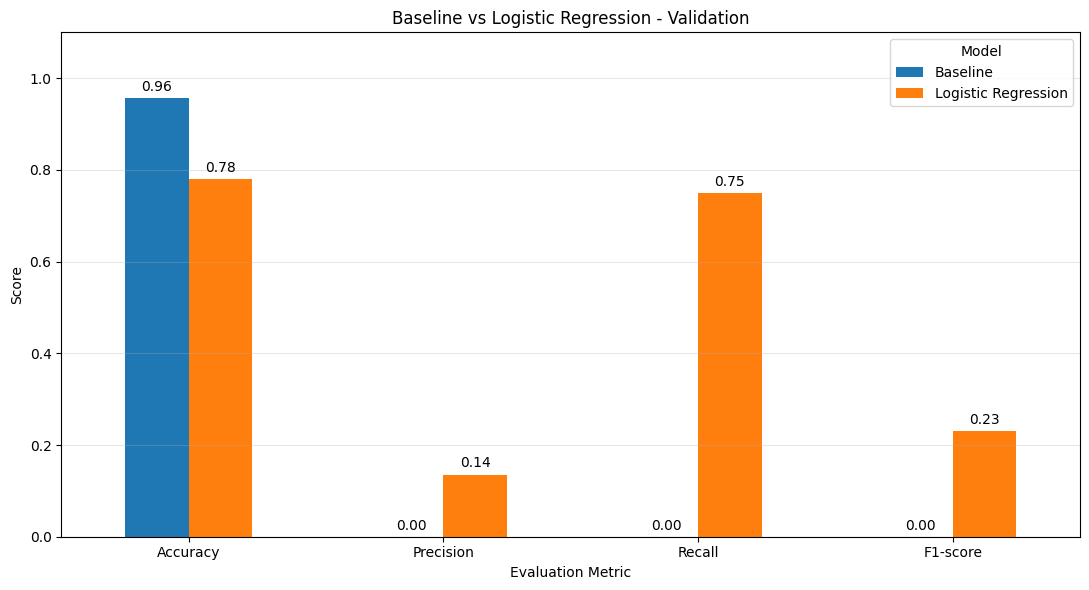

In [20]:
# Check accuracy directly from predictions
print("Logistic Accuracy:",accuracy_score(y_val, y_logistic))

# Plot baseline vs Logistic Regression
plot_df = comparison_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].T

ax = plot_df.plot(kind="bar",figsize=(11, 6),rot=0)

plt.title("Baseline vs Logistic Regression - Validation")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.1)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

Although the baseline achieved an accuracy of 95.6%, it failed to detect any flood cases. Logistic Regression achieved a recall of 75%, correctly identifying 24 out of 32 flood-labeled days in the validation dataset. This demonstrates why accuracy alone is not a reliable evaluation metric for imbalanced flood prediction.